In [1]:
import os
import sys
import warnings
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import RobustScaler
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import IsolationForest
sys.path.append(os.path.abspath('..'))
%load_ext autoreload
%autoreload 2
from utils_2 import histograma_simples,resumo_estatistico,plot_boxplot_outliers,plot_distribuicao,resumo_estatistico_numerico,analisar_multicolinearidade_pares,plot_matriz_correlacao

from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

warnings.filterwarnings('ignore')


In [2]:
%matplotlib widget

In [3]:
# Configurando o diretório

# OBS = O arquivo é puxado dentro de data/processed

nome_arquivo = 'master.csv'

DIR_ATUAL = os.getcwd() 

DIR_ARQ  = os.path.join(DIR_ATUAL,'..','data','processed', nome_arquivo)


X = pd.read_csv(DIR_ARQ)

display(X.head(20))

,room_type,availability_365,price_log,reviews_per_month_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square,custo_estadia_log,volume_oferta_dias_anfitriao_log,taxa_reviews_mes
0,1,365,5.010635,0.190620,1,0,0,0,0.111287,5.010635,2190,42.856939
1,2,355,5.420535,0.322083,0,1,0,0,0.004709,5.420535,710,118.420741
2,1,365,5.017280,0.000000,0,1,0,0,0.067112,6.111467,365,0.000000
3,2,194,4.499810,1.729884,1,0,0,0,0.077273,4.499810,194,58.189643
4,2,0,4.394449,0.095310,0,1,0,0,0.058001,6.685861,0,89.999100
5,2,129,5.303305,0.463734,0,1,0,0,0.014730,6.398595,129,125.423516
6,1,0,4.110874,0.336472,1,0,0,0,0.077011,7.901377,0,122.499694
7,1,220,4.382027,1.497388,0,1,0,0,0.006914,5.068904,220,123.919273
8,1,0,4.382027,0.688135,0,1,0,0,0.047439,5.068904,0,119.191799
9,2,188,5.017280,0.845868,0,1,0,0,0.044825,5.017280,752,120.300661


In [4]:
X.head(10)

,room_type,availability_365,price_log,reviews_per_month_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square,custo_estadia_log,volume_oferta_dias_anfitriao_log,taxa_reviews_mes
0,1,365,5.010635,0.190620,1,0,0,0,0.111287,5.010635,2190,42.856939
1,2,355,5.420535,0.322083,0,1,0,0,0.004709,5.420535,710,118.420741
2,1,365,5.017280,0.000000,0,1,0,0,0.067112,6.111467,365,0.000000
3,2,194,4.499810,1.729884,1,0,0,0,0.077273,4.499810,194,58.189643
4,2,0,4.394449,0.095310,0,1,0,0,0.058001,6.685861,0,89.999100
5,2,129,5.303305,0.463734,0,1,0,0,0.014730,6.398595,129,125.423516
6,1,0,4.110874,0.336472,1,0,0,0,0.077011,7.901377,0,122.499694
7,1,220,4.382027,1.497388,0,1,0,0,0.006914,5.068904,220,123.919273
8,1,0,4.382027,0.688135,0,1,0,0,0.047439,5.068904,0,119.191799
9,2,188,5.017280,0.845868,0,1,0,0,0.044825,5.017280,752,120.300661


In [5]:
X_limpo = X

In [6]:
# Remoção de Outliers

limite_inferior = X.quantile(0.01)
limite_superior = X.quantile(0.99)

# CLipagem dos limites
X_clipado = X.clip(lower=limite_inferior, upper=limite_superior, axis=1)

X = X_clipado


# RobustScaler — normalização via mediana e IQR
padronizador = RobustScaler().fit(X)

X_tratado = pd.DataFrame(
    padronizador.transform(X),
    columns=X.columns,
    index=X.index
)

In [7]:
X_tratado.head(10)

,room_type,availability_365,price_log,reviews_per_month_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square,custo_estadia_log,volume_oferta_dias_anfitriao_log,taxa_reviews_mes
0,-1.0,1.409692,0.366389,-0.136688,1.0,0.0,0.0,0.0,0.841965,-0.412629,6.516820,0.817710
1,0.0,1.365639,0.810971,0.008005,0.0,1.0,0.0,0.0,-1.096765,-0.169783,1.990826,2.292574
2,-1.0,1.409692,0.373596,-0.346491,0.0,1.0,0.0,0.0,0.033567,0.239563,0.935780,-0.427163
3,0.0,0.656388,-0.187659,1.557475,1.0,0.0,0.0,0.0,0.219514,-0.715270,0.412844,1.263082
4,0.0,-0.198238,-0.301934,-0.241589,0.0,1.0,0.0,0.0,-0.133155,0.579865,-0.180428,2.187056
5,0.0,0.370044,0.683822,0.163910,0.0,1.0,0.0,0.0,-0.925015,0.409673,0.214067,2.292574
6,-1.0,-0.198238,-0.609503,0.023841,1.0,0.0,0.0,0.0,0.214715,1.300002,-0.180428,2.292574
7,-1.0,0.770925,-0.315408,1.301583,0.0,1.0,0.0,0.0,-1.068046,-0.378108,0.492355,2.292574
8,-1.0,-0.198238,-0.315408,0.410892,0.0,1.0,0.0,0.0,-0.326437,-0.378108,-0.180428,2.292574
9,0.0,0.629956,0.373596,0.584499,0.0,1.0,0.0,0.0,-0.374270,-0.408693,2.119266,2.292574


# (2.0) Modelando com K-Means

K-Means é um algoritmo que funciona por meio da seguinte premissa:

-  Dado um conjunto de `n` pontos, é possível separá-lo em `k` grupos/clusters com pontos semelhantes entre si.

Cada grupo (cluster) possui um **centróide**, que é atribuído como o centro de cada cluster. Ele **não necessariamente é um ponto real do dataset**.

### Fórmula do centróide

$$
\mu_k = \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i
$$

Onde:
- `C_k` = conjunto de pontos atribuídos ao cluster `k`
- `|C_k|` = número de pontos no cluster `k`
- `x_i` = vetor de features do ponto `i`

Ou seja, o centróide é a **média** dos pontos do cluster, feature por feature.

### Distância Euclidiana

Definimos a distância euclidiana entre dois pontos (ou entre um ponto e um centróide) como:

$$
d(x, \mu) = \sqrt{\sum_{j=1}^{d} (x_j - \mu_j)^2}
$$

Onde:
- `d` = número de features (dimensões)
- `x_j` = valor da feature `j` do ponto `x`
- `μ` = valor da feature `j` do centróide `μ`

Na prática, o K-Means usa a **distância euclidiana ao quadrado** (sem a raiz), pois é mais barato computacionalmente e leva ao mesmo resultado de atribuição:

$$
\|x - \mu\|^2 = \sum_{j=1}^{d} (x_j - \mu_j)^2
$$

> Por isso, de modo a não enviesar a análise, é extremamente importante **padronizar os dados de entrada** (a matriz). Features com escalas diferentes dominariam o cálculo da distância.

---

## Ciclo do Cluster

O algoritmo é iterativo e alterna entre atribuição e recálculo dos centros:

**1) Inicializar centros aleatórios espalhados (Forgy)**

Escolher `k` centróides iniciais. `O método de Forgy sorteia `k` pontos reais do dataset como centros iniciais`. (Uma alternativa melhor é o **K-Means++**, que escolhe centros espalhados proporcionalmente à **distância² ao centro mais próximo** já escolhido.)

**2) Atribuir cada ponto ao centróide mais próximo**

Para cada ponto, calcula-se a distância até cada um dos `k` centróides e atribui-se o ponto ao centróide mais próximo:

$$
\text{cluster}(x_i) = \arg\min_{k=1,\dots,K} \|x_i - \mu_k\|^2
$$

**3) Recalcular os centróides**

Para cada centróide, recalcula-se sua posição com base nos pontos do seu próprio cluster, de modo a corrigir sua posição:

$$
\mu_k \leftarrow \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i
$$

**4) Repetir até convergir**

Repete-se o passo 2 e o passo 3 até que:
- as atribuições não mudem mais, ou
- os centróides se movam menos que uma tolerância `ε`, ou
- atinja-se um número máximo de iterações.

> Cada passo nunca aumenta a inércia, então o algoritmo converge — mas para um **mínimo local**. Por isso é comum rodar várias inicializações (`n_init`) e ficar com a de menor inércia.

---

## Métricas de Avaliação

Como não há rótulos verdadeiros, avaliamos a qualidade geométrica da partição: **coesão** (pontos perto do seu centróide) e **separação** (clusters longe uns dos outros).

### Inertia (WCSS — Within-Cluster Sum of Squares)

$$
\text{Inertia} = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2
$$

- **Menor é melhor** (é o objetivo que o K-Means minimiza).
- **Não serve para comparar `k` diferentes**, pois sempre diminui quando `k` aumenta.
- Uso clássico: **método do cotovelo (elbow)** — plotar inércia vs. `k` e procurar o "joelho" da curva.

### Silhouette (Coeficiente de Silhueta)

Para cada ponto `i`:
- `a(i)` = distância média aos outros pontos do **mesmo cluster** (coesão)
- `b(i)` = distância média aos pontos do **cluster vizinho mais próximo** (separação)

$$
s(i) = \frac{b(i) - a(i)}{\max(a(i),\, b(i))} \in [-1, 1]
$$

O silhouette final é a média dos `s(i)`.

- **Maior é melhor** (perto de +1 = ponto bem dentro do seu cluster).
- Perto de 0 = ponto na fronteira entre clusters.
- Negativo = ponto provavelmente atribuído ao cluster errado.
- **Compara `k` diferentes.**
- Custo `O(n²)` (distâncias par a par) — caro para `n` grande.

### Davies-Bouldin

Para cada par de clusters `i, j`, mede a similaridade:

$$
R_{ij} = \frac{s_i + s_j}{d(\mu_i,\, \mu_j)}
$$

Onde `s_i` é a dispersão média dos pontos do cluster `i` ao seu centróide, e `d(\mu_i, \mu_j)` é a distância entre os centróides. A métrica final é:

$$
\text{DB} = \frac{1}{K} \sum_{i=1}^{K} \max_{j \neq i} R_{ij}
$$

- Mede a razão **dispersão interna / separação entre clusters**.
- **Menor é melhor** (0 é o ideal).
- **Compara `k` diferentes.**

### Calinski-Harabasz (Variance Ratio Criterion)

Razão entre a dispersão **entre** clusters e a dispersão **dentro** dos clusters, normalizadas pelos graus de liberdade:

$$
\text{CH} = \frac{\operatorname{tr}(B_K)/(K-1)}{\operatorname{tr}(W_K)/(n-K)}
$$

Onde:
- `B_K` = matriz de dispersão **entre** clusters
- `W_K` = matriz de dispersão **dentro** dos clusters
- `K` = número de clusters
- `n` = número de pontos

- **Maior é melhor** (clusters compactos e bem separados).
- **Compara `k` diferentes.**
- Custo `O(n)`, relativamente barato.

---

## Resumo Comparativo

| Métrica | O que mede | Direção | Compara `k`? | Custo |
|---|---|---|---|---|
| **Inertia** | coesão interna (SSE) | menor melhor | não | `O(nKd)` |
| **Silhouette** | coesão vs. separação | maior melhor | sim | `O(n²)` |
| **Davies-Bouldin** | dispersão / separação | menor melhor | sim | `O(nKd + K²d)` |
| **Calinski-Harabasz** | variância entre / dentro | maior melhor | sim | `O(nKd)` |


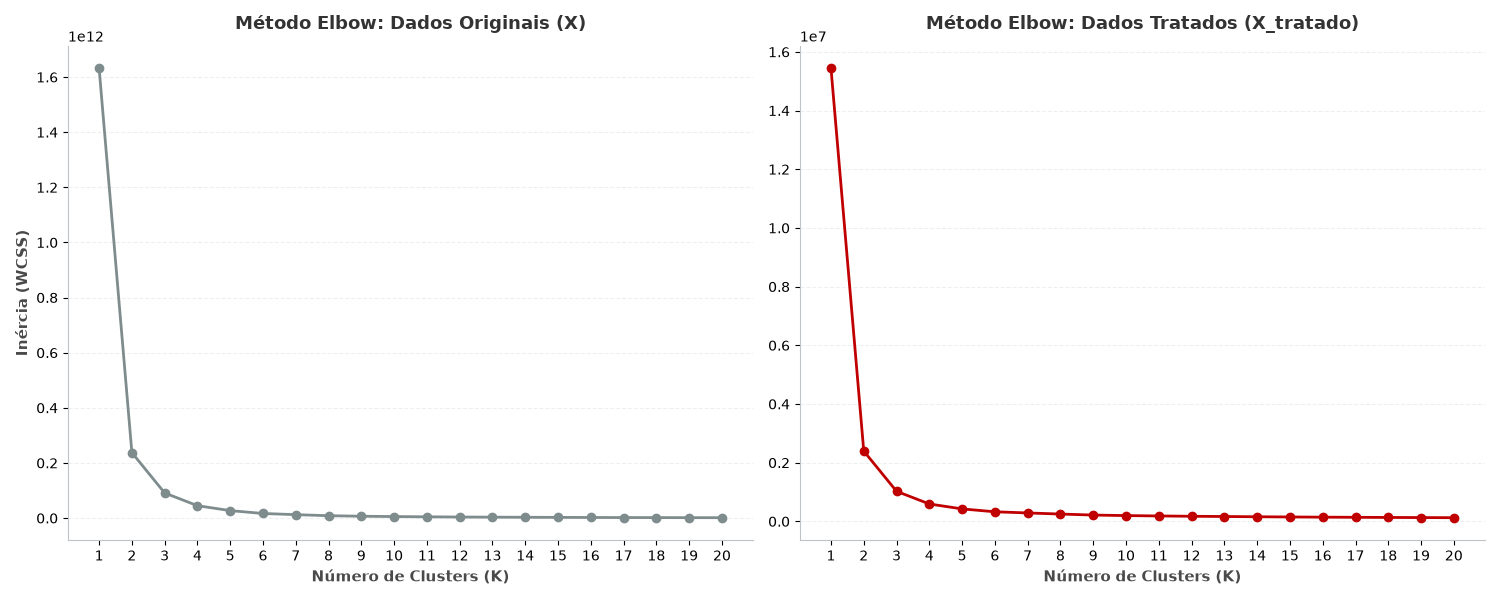

In [8]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Correção da lista de valores de K
k_valores = list(range(1, 21))

# 2. Criação de listas separadas para armazenar as inércias
inercias_x = []
inercias_x_tratado = []

# 3. Loop unificado para treinar e capturar a inércia dos dois datasets
for k in k_valores:
    modelo_km = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=20,
        max_iter=300,
        random_state=10
    )
    
    # Treino e captura para o X original
    modelo_km.fit(X)
    inercias_x.append(modelo_km.inertia_)
    
    # Treino e captura para o X tratado
    modelo_km.fit(X_tratado)
    inercias_x_tratado.append(modelo_km.inertia_)

# 4. Configuração dos subplots: 1 linha e 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 5. Paleta de cores corporativa
cor_base = '#7F8C8D'     # Cinza para o X Original (baseline)
cor_destaque = '#C00000' # Vermelho para o X Tratado (foco da análise)

# --- GRÁFICO 1: X ORIGINAL (axes[0]) ---
axes[0].plot(k_valores, inercias_x, marker='o', markersize=6, color=cor_base, linewidth=2)
axes[0].set_title('Método Elbow: Dados Originais (X)', fontsize=13, fontweight='bold', color='#333333', pad=12)
axes[0].set_xlabel('Número de Clusters (K)', fontsize=11, fontweight='bold', color='#4A4A4A')
axes[0].set_ylabel('Inércia (WCSS)', fontsize=11, fontweight='bold', color='#4A4A4A')
axes[0].set_xticks(k_valores)

# Limpeza visual e grid
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].spines['left'].set_color('#BDC3C7')
axes[0].spines['bottom'].set_color('#BDC3C7')
axes[0].grid(axis='y', linestyle='--', alpha=0.4, color='#D5D8DC')

# --- GRÁFICO 2: X TRATADO (axes[1]) ---
axes[1].plot(k_valores, inercias_x_tratado, marker='o', markersize=6, color=cor_destaque, linewidth=2)
axes[1].set_title('Método Elbow: Dados Tratados (X_tratado)', fontsize=13, fontweight='bold', color='#333333', pad=12)
axes[1].set_xlabel('Número de Clusters (K)', fontsize=11, fontweight='bold', color='#4A4A4A')
axes[1].set_xticks(k_valores)

# Limpeza visual e grid (replica do primeiro)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].spines['left'].set_color('#BDC3C7')
axes[1].spines['bottom'].set_color('#BDC3C7')
axes[1].grid(axis='y', linestyle='--', alpha=0.4, color='#D5D8DC')

plt.tight_layout()
plt.show()

In [9]:
k_valores = range(2, 11)
resultados_metricas = []

for k in k_valores:
    km = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10, 
        max_iter=300, 
        random_state=10
    )
    labels = km.fit_predict(X_tratado)
    
    # 1 Contagem
    valores_unicos, contagens = np.unique(labels, return_counts=True)
    distribuicao_tamanhos = {int(cluster): int(qtd) for cluster, qtd in zip(valores_unicos, contagens)}
    
    # 2. Silhouette com subsample de 10.000 pontos 
    sil = silhouette_score(X_tratado, labels, sample_size=10000, random_state=10)
    
    resultados_metricas.append({
        'K': k,
        'Inertia': km.inertia_,
        'Silhouette': sil,
        'Davies_Bouldin': davies_bouldin_score(X_tratado, labels),
        'Calinski_Harabasz': calinski_harabasz_score(X_tratado, labels),
        'Tamanho_dos_Clusters': distribuicao_tamanhos
    })

df_resultados = pd.DataFrame(resultados_metricas)

colunas_float = ['Inertia', 'Silhouette', 'Davies_Bouldin', 'Calinski_Harabasz']
df_resultados[colunas_float] = df_resultados[colunas_float].round(2) #arred 2 casas

display(df_resultados)

,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,Tamanho_dos_Clusters
0,2,2398915.68,0.95,0.28,265925.09,"{0: 47723, 1: 1172}"
1,3,1025543.18,0.91,0.41,343752.34,"{0: 47021, 1: 871, 2: 1003}"
2,4,593083.25,0.89,0.38,408146.60,"{0: 46840, 1: 608, 2: 482, 3: 965}"
3,5,425203.00,0.73,0.49,431786.45,"{0: 45418, 1: 608, 2: 469, 3: 1680, 4: 720}"
4,6,327110.43,0.68,0.50,451938.36,"{0: 44869, 1: 344, 2: 427, 3: 596, 4: 2011, 5:..."
5,7,287752.19,0.67,0.48,429233.53,"{0: 44834, 1: 596, 2: 316, 3: 2028, 4: 633, 5:..."
6,8,249767.18,0.21,0.81,424940.67,"{0: 22190, 1: 276, 2: 596, 3: 630, 4: 1960, 5:..."
7,9,215425.59,0.22,0.82,432046.79,"{0: 21158, 1: 276, 2: 508, 3: 596, 4: 812, 5: ..."
8,10,197583.64,0.21,0.88,419199.21,"{0: 305, 1: 1752, 2: 596, 3: 276, 4: 480, 5: 1..."


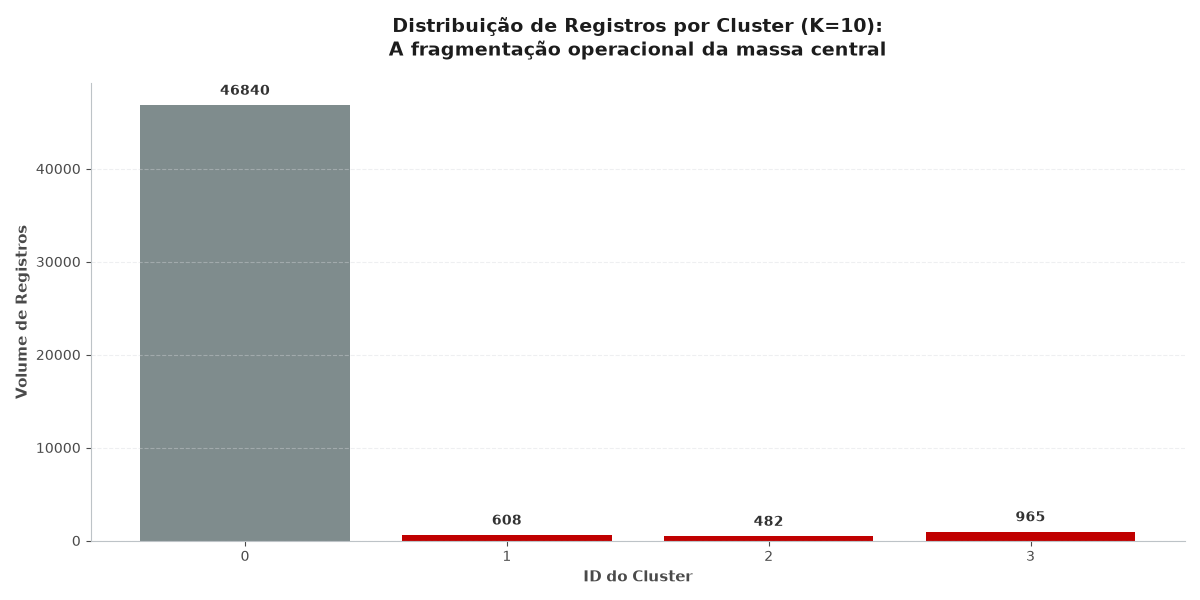

In [10]:
import matplotlib.pyplot as plt

# 1. Dados atualizados para K=10 (atribuição corrigida)
tamanhos_k10 = {0: 46840, 1: 608, 2: 482, 3: 965}
fig, ax = plt.subplots(figsize=(12, 6))

# 2. Paleta de Cores Corporativa
# Cinza base para os macro-clusters (> 10.000) e Vermelho de destaque para os nichos
cores = ['#7F8C8D' if v > 10000 else '#C00000' for v in tamanhos_k10.values()]

# 3. Plotagem das barras
barras = ax.bar(tamanhos_k10.keys(), tamanhos_k10.values(), color=cores, edgecolor='none')

# 4. Título Executivo e Rótulos dos Eixos
ax.set_title('Distribuição de Registros por Cluster (K=10):\nA fragmentação operacional da massa central', 
             fontsize=14, fontweight='bold', color='#1C1C1C', pad=20)
ax.set_xlabel('ID do Cluster', fontsize=11, fontweight='bold', color='#4A4A4A')
ax.set_ylabel('Volume de Registros', fontsize=11, fontweight='bold', color='#4A4A4A')

# 5. Adição dos rótulos de dados exatos no topo das barras
ax.bar_label(barras, fmt='{:.0f}', padding=5, color='#333333', fontweight='bold', fontsize=10)

# 6. Limpeza Visual
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#BDC3C7')
ax.spines['bottom'].set_color('#BDC3C7')

# Ajuste dos ticks do eixo X para exibir todos os IDs e formatação do grid
ax.set_xticks(list(tamanhos_k10.keys()))
ax.tick_params(axis='both', which='major', labelsize=10, colors='#4A4A4A')
ax.grid(axis='y', linestyle='--', alpha=0.4, color='#D5D8DC')

plt.tight_layout()
plt.show()

In [11]:
import plotly.express as px
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 1. Garantir que o modelo final está treinado com K=4
km_final = KMeans(n_clusters=4, init='k-means++', n_init=10, max_iter=300, random_state=10)
labels_k4 = km_final.fit_predict(X_tratado)

# 2. Redução de Dimensionalidade (PCA) para 2 componentes (2D)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_tratado)

# 3. Construção do DataFrame para o Plotly
df_pca = pd.DataFrame(X_pca, columns=['Componente 1', 'Componente 2'])
df_pca['Cluster'] = labels_k4.astype(str)  # Plotly exige strings para categorizar as cores corretamente

# 4. Mapeamento da Paleta Corporativa
# O Cluster 0 (gigante) fica em cinza, os nichos ganham tons de vermelho/bordeaux
mapa_cores = {0: '#7F8C8D', 1: '#C00000', 2: "#007006", 3: "#A6FF00"}

# Tiramos uma amostra de 5000 pontos para o SVG não travar o seu ambiente
df_pca_amostra = df_pca.sample(n=5000, random_state=42)

fig = px.scatter(
    df_pca_amostra,
    x='Componente 1',
    y='Componente 2',
    color='Cluster',
    color_discrete_map=mapa_cores,
    opacity=0.6,
    render_mode='svg', # <-- Força a fugir do WebGL
    title='Visualização 2D',
    hover_data={'Componente 1': False, 'Componente 2': False, 'Cluster': True}
)

# 6. Formatação Executiva do Layout
fig.update_layout(
    plot_bgcolor='white',
    title_font=dict(size=18, color='#1C1C1C', family='Arial'),
    legend_title_text='ID do Cluster',
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    ),
    width=900,
    height=600
)

# Adicionando grade sutil
fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor='#E5E7E9', title_font=dict(size=12, color='#4A4A4A'))
fig.update_yaxes(showgrid=True, gridwidth=1, gridcolor='#E5E7E9', title_font=dict(size=12, color='#4A4A4A'))

fig.show()

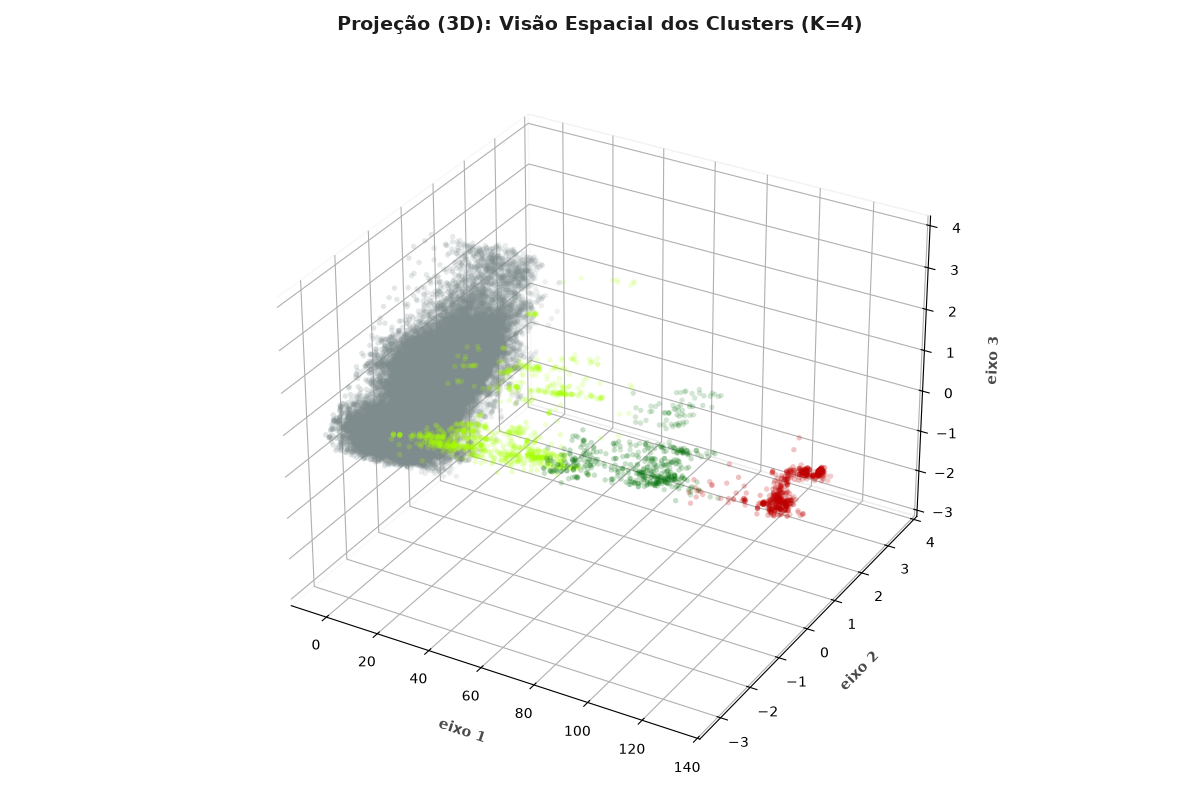

In [12]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

# 1. Redução para 3 dimensões (Componentes Principais)
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_tratado)

# 2. Configuração do ambiente 3D
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# 3. Mapeamento de cores corporativas baseado nos labels do K=4
cores_dict = {0: '#7F8C8D', 1: '#C00000', 2: "#007006", 3: "#A6FF00"}
# Cria uma lista de cores correspondente a cada ponto da base
cores_pontos = [cores_dict[label] for label in labels_k4]

# 4. Plotagem dos pontos
# Usamos alpha=0.2 (alta transparência) porque 48 mil pontos sobrepostos viram um bloco sólido
ax.scatter(
    X_pca_3d[:, 0], 
    X_pca_3d[:, 1], 
    X_pca_3d[:, 2], 
    c=cores_pontos, 
    s=15,               # Tamanho do ponto
    alpha=0.5,          # Transparência
    edgecolors='none'
)

# 5. Formatação Executiva 3D
ax.set_title('Projeção (3D): Visão Espacial dos Clusters (K=4)', 
             fontsize=14, fontweight='bold', color='#1C1C1C', pad=20)
ax.set_xlabel('eixo 1', fontweight='bold', color='#4A4A4A', labelpad=10)
ax.set_ylabel('eixo 2', fontweight='bold', color='#4A4A4A', labelpad=10)
ax.set_zlabel('eixo 3', fontweight='bold', color='#4A4A4A', labelpad=10)

# Limpeza visual: remove o fundo cinza padrão dos painéis 3D do Matplotlib
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

# Suaviza as linhas de grade para não poluir os dados
ax.grid(True, linestyle='--', alpha=0.3, color='#D5D8DC')

plt.tight_layout()
plt.show()